# Split-stats summary

High/low (`AGNLUM`) split profiles for each profile type, with jackknife errorbars, shown for **BGS**, **LRG**, and **BGS+LRG** (deduplicated).

- **Blue** = low split, **red** = high split
- 90 GHz = solid, 150 GHz = dashed (shown on the same axes)
- One column per galaxy sample (BGS / LRG / BGS+LRG)
- Profiles are divided by the ring area `a` (as in `noah_scratch.ipynb`); errors are divided by `a` too.

In [82]:
datadir = ''
datafn = f'{datadir}LRGonly_smallerRadii_fixedColnames.fits'
data1 = Table.read(datafn)

datadir = '../../desi_dr1_runs/'
datafn = f'{datadir}90.150.kappa.compy_overlap_BgsLrgDuplicates.fits'
data2 = Table.read(datafn)
data2=data2[data2['galaxy_type']=='lrg']

len(data1)-len(data2)

0

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
from astropy.table import Table
sys.path.append("../")
from boxeyFeedback import high_low_split
from jackknifing import jackknife_weighted_mean_cov_fast2

#r = np.loadtxt('../small_radius.txt')
#a = np.loadtxt('../small_area.txt')


def get_split_profile_stats(data, split_property):
    stats = {}
    for key1 in data.keys():
        for hl1 in [f'high_{split_property}', f'low_{split_property}']:
            d1 = data[data['split'] == hl1][key1]
            for key2 in data.keys():
                for hl2 in [f'high_{split_property}', f'low_{split_property}']:
                    d2 = data[data['split'] == hl2][key2]
                    if key1.startswith('profile_') and key2.startswith('profile_'):
                        w1 = np.ones(len(d1))
                        w2 = np.ones(len(d2))
                        m1, m2, c11, c22, c12 = jackknife_weighted_mean_cov_fast2(d1, w1, d2, w2)
                        stats[f'{key1}-{hl1}_mean'] = m1
                        stats[f'{key2}-{hl2}_mean'] = m2
                        stats[f'{key1}-{hl1}_cov'] = c11
                        stats[f'{key2}-{hl2}_cov'] = c22
                        stats[f'{key1}-{hl1}_{key2}-{hl2}_cov'] = c12
                    continue
    return stats

In [2]:
# read in data (modify this to read in your data)
datadir = '../../desi_dr1_runs/'
datafn = f'{datadir}90.150.kappa.compy_overlap_BgsLrgDuplicates.fits'
data = Table.read(datafn)
# apply cuts to data
data = data[data['Z'] < 1.3]
data = data[data['LOGM'] > 10.9]
data = data[data['LOGM'] < 12.5]
data = data[(data['catmask_ring_kappa']==True)&(data['catmask_ringring2_90ghz']==True)&(data['catmask_ringring2_150ghz']==True)&(data['catmask_ringring2_compy']==True)]
# make separate dataframes for bgs, lrg and bgs+lrg
bgs = data.copy()
bgs = bgs[bgs['galaxy_type']=='bgs']
lrg = data.copy()
lrg = lrg[lrg['galaxy_type']=='lrg']
bgs_lrg = data.copy()
bgs_lrg = bgs_lrg[(bgs_lrg['galaxy_type']=='bgs') | ((bgs_lrg['galaxy_type']=='lrg') & (~bgs_lrg['duplicate']))]
# box-ify data
split_property = 'AGNLUM'
n_boxes = 100
#data_bgs = high_low_split(bgs, split_property, n_boxes=n_boxes)
data_lrg = high_low_split(lrg, split_property, n_boxes=n_boxes)
data_bgs_lrg = high_low_split(bgs_lrg, split_property, n_boxes=n_boxes)
# compute profile stats
#profile_stats_bgs = get_split_profile_stats(data_bgs, split_property)
profile_stats_lrg = get_split_profile_stats(data_lrg, split_property)
profile_stats_bgs_lrg = get_split_profile_stats(data_bgs_lrg, split_property)

In [3]:
# read in data (modify this to read in your data)
#datadir = '../../desi_dr1_runs/'
datadir = ''
datafn = f'{datadir}LRGonly_smallerRadii_fixedColnames.fits'
data = Table.read(datafn)
# apply cuts to data
data = data[data['Z'] < 1.3]
data = data[data['LOGM'] > 10.9]
data = data[data['LOGM'] < 12.5]
data = data[(data['catmask_ring_kappa']==True)&(data['catmask_ringring2_90ghz']==True)&(data['catmask_ringring2_150ghz']==True)&(data['catmask_ringring2_compy']==True)]
# make separate dataframes for bgs, lrg and bgs+lrg
bgs = data.copy()
bgs = bgs[bgs['galaxy_type']=='bgs']
lrg = data.copy()
lrg = lrg[lrg['galaxy_type']=='lrg']
bgs_lrg = data.copy()
bgs_lrg = bgs_lrg[(bgs_lrg['galaxy_type']=='bgs') | ((bgs_lrg['galaxy_type']=='lrg') & (~bgs_lrg['duplicate']))]
# box-ify data
split_property = 'AGNLUM'
n_boxes = 100
#data_bgs = high_low_split(bgs, split_property, n_boxes=n_boxes)
data_lrg = high_low_split(lrg, split_property, n_boxes=n_boxes)
data_bgs_lrg = high_low_split(bgs_lrg, split_property, n_boxes=n_boxes)
# compute profile stats
#profile_stats_bgs = get_split_profile_stats(data_bgs, split_property)
profile_stats_lrg_low = get_split_profile_stats(data_lrg, split_property)
profile_stats_bgs_lrg_low = get_split_profile_stats(data_bgs_lrg, split_property)

In [4]:
def get_split(profile_stats, profile_col, hl, a):
    """Return (mean, error) for one profile column and split, normalized by ring area.

    profile_stats : one of the per-sample stats dicts (bgs / lrg / bgs+lrg)
    profile_col   : e.g. 'profile_ringring2_90ghz' or 'profile_ring_kappa'
    hl            : 'high' or 'low'
    """
    base = f'{profile_col}-{hl}_{split_property}'
    mean = profile_stats[f'{base}_mean'] / a
    err = np.diag(profile_stats[f'{base}_cov']) ** 0.5 / a
    return mean, err


# (label, stats dict) for each galaxy sample, one column per case
'''
cases = [('BGS', profile_stats_bgs),
         ('LRG', profile_stats_lrg),
         ('BGS+LRG', profile_stats_bgs_lrg)]
'''
cases_low = [('LRG', profile_stats_lrg_low),
         ('BGS+LRG', profile_stats_bgs_lrg_low)]

cases = [('LRG', profile_stats_lrg),
         ('BGS+LRG', profile_stats_bgs_lrg)]

color = {'low': 'tab:blue', 'high': 'tab:red'}
color_low = {'low': 'tab:green', 'high': 'tab:orange'}

Blue = low, red = high; 90 GHz solid, 150 GHz dashed. One column per galaxy sample.

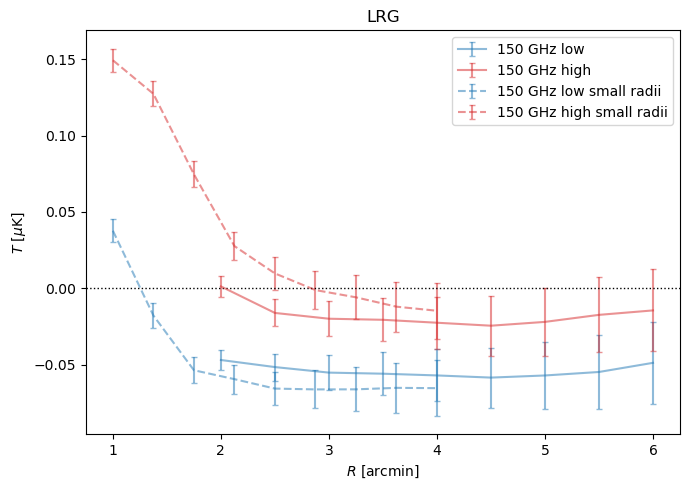

In [5]:
'''ghz_styles = [('profile_ringring2_90ghz', '-', '90 GHz'),
              ('profile_ringring2_150ghz', '--', '150 GHz')]
              '''
ghz_styles = [('profile_ringring2_150ghz', '-', '150 GHz')]

r_low = np.loadtxt('../small_radius.txt')
a_low = np.loadtxt('../small_area.txt')

r = np.loadtxt('../radius.txt')
a = np.loadtxt('../area.txt')

fig, ax = plt.subplots(1, 1, figsize=(7, 5), sharey=True)

for profile_col, ls, freq_label in ghz_styles:
    for hl in ['low', 'high']:
        mean, err = get_split(profile_stats_lrg, profile_col, hl, a)
        ax.errorbar(r, mean, yerr=err, color=color[hl], linestyle=ls,
                    capsize=2, label=f'{freq_label} {hl}', alpha=0.5)

for profile_col, ls, freq_label in ghz_styles:
    for hl in ['low', 'high']:
        mean, err = get_split(profile_stats_lrg_low, profile_col, hl, a_low)
        ax.errorbar(r_low, mean, yerr=err, color=color[hl], linestyle='--',
                    capsize=2, label=f'{freq_label} {hl} small radii', alpha=0.5)
ax.axhline(0, color='black', linewidth=1, linestyle=':')
ax.set_xlabel(r'$R$ [arcmin]')
ax.set_title(f'LRG')
ax.legend()

ax.set_ylabel(r'$T$ [$\mu$K]')
#fig.suptitle(f'90 & 150 GHz profiles split on {split_property}')
plt.tight_layout()
plt.show()

## Radio

In [6]:
import astropy.units as u
from astropy.coordinates import SkyCoord

def crossmatch_flag(radio_table, cmb_table, radius_arcsec):
    coords_rad = SkyCoord(ra=radio_table['RA']*u.deg, dec=radio_table['DEC']*u.deg) # only need to add degrees to radio table bc i already added them in our table
    coords_cmb = SkyCoord(ra=cmb_table['RA'], dec=cmb_table['DEC'])
    
    rad_matched_id, dist2match, _ = coords_cmb.match_to_catalog_sky(coords_rad) # looks at the cmb table, determines the closest object from the radio table, and calculates the radial distance

    keep_mask = dist2match > (radius_arcsec * u.arcsec) # keep all objects are more than your set radius flag
    
    matched_ids = np.array(radio_table['Component_name'][rad_matched_id]) # take the rad_matched_id index and saves the actual comp name, denoting the closest object
    
    matched_ids[keep_mask] = None # if we're keeping the objects, then don't name the ID in the table
    
    cmb_table['keep_flag'] = keep_mask
    cmb_table['radio_obj_match'] = matched_ids
    
    return cmb_table

In [9]:
import pandas as pd
df = pd.read_csv('../../desi_dr1_runs/CIRADA_VLASS1QLv3.1_table1_components.csv')
rad = Table.from_pandas(df)

In [29]:
# read in data (modify this to read in your data)
datadir = '../../desi_dr1_runs/'
datafn = f'{datadir}90.150.kappa.compy_overlap_BgsLrgDuplicates.fits'
data = Table.read(datafn)
data = crossmatch_flag(rad, data, 3)
data = data[data['keep_flag']==True]
# apply cuts to data
data = data[data['Z'] < 1.3]
data = data[data['LOGM'] > 10.9]
data = data[data['LOGM'] < 12.5]
data = data[(data['catmask_ring_kappa']==True)&(data['catmask_ringring2_90ghz']==True)&(data['catmask_ringring2_150ghz']==True)&(data['catmask_ringring2_compy']==True)]
# make separate dataframes for bgs, lrg and bgs+lrg
bgs = data.copy()
bgs = bgs[bgs['galaxy_type']=='bgs']
lrg = data.copy()
lrg = lrg[lrg['galaxy_type']=='lrg']
bgs_lrg = data.copy()
bgs_lrg = bgs_lrg[(bgs_lrg['galaxy_type']=='bgs') | ((bgs_lrg['galaxy_type']=='lrg') & (~bgs_lrg['duplicate']))]
# box-ify data
split_property = 'AGNLUM'
n_boxes = 100
#data_bgs = high_low_split(bgs, split_property, n_boxes=n_boxes)
data_lrg = high_low_split(lrg, split_property, n_boxes=n_boxes)
data_bgs_lrg = high_low_split(bgs_lrg, split_property, n_boxes=n_boxes)
# compute profile stats
#profile_stats_bgs = get_split_profile_stats(data_bgs, split_property)
profile_stats_norad_lrg = get_split_profile_stats(data_lrg, split_property)
profile_stats_norad_bgs_lrg = get_split_profile_stats(data_bgs_lrg, split_property)

In [30]:
# read in data (modify this to read in your data)
#datadir = '../../desi_dr1_runs/'
datadir = ''
datafn = f'{datadir}LRGonly_smallerRadii_fixedColnames.fits'
data = Table.read(datafn)
data = crossmatch_flag(rad, data, 3)
data = data[data['keep_flag']==True]
# apply cuts to data
data = data[data['Z'] < 1.3]
data = data[data['LOGM'] > 10.9]
data = data[data['LOGM'] < 12.5]
data = data[(data['catmask_ring_kappa']==True)&(data['catmask_ringring2_90ghz']==True)&(data['catmask_ringring2_150ghz']==True)&(data['catmask_ringring2_compy']==True)]
# make separate dataframes for bgs, lrg and bgs+lrg
bgs = data.copy()
bgs = bgs[bgs['galaxy_type']=='bgs']
lrg = data.copy()
lrg = lrg[lrg['galaxy_type']=='lrg']
bgs_lrg = data.copy()
bgs_lrg = bgs_lrg[(bgs_lrg['galaxy_type']=='bgs') | ((bgs_lrg['galaxy_type']=='lrg') & (~bgs_lrg['duplicate']))]
# box-ify data
split_property = 'AGNLUM'
n_boxes = 100
#data_bgs = high_low_split(bgs, split_property, n_boxes=n_boxes)
data_lrg = high_low_split(lrg, split_property, n_boxes=n_boxes)
data_bgs_lrg = high_low_split(bgs_lrg, split_property, n_boxes=n_boxes)
# compute profile stats
#profile_stats_bgs = get_split_profile_stats(data_bgs, split_property)
profile_stats_norad_lrg_low = get_split_profile_stats(data_lrg, split_property)
profile_stats_norad_bgs_lrg_low = get_split_profile_stats(data_bgs_lrg, split_property)

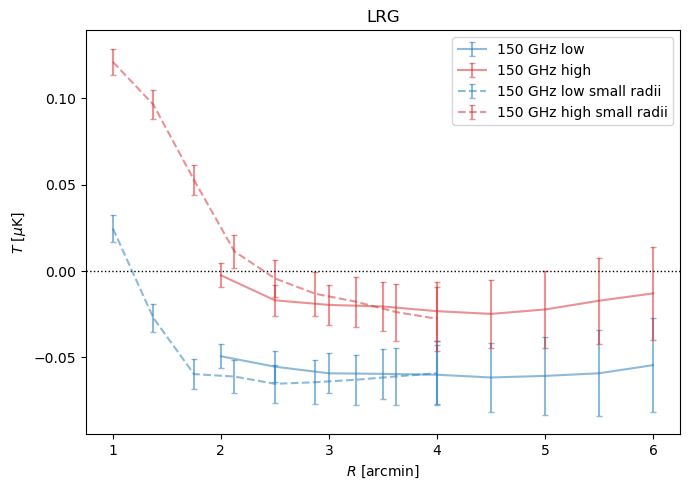

In [31]:
'''ghz_styles = [('profile_ringring2_90ghz', '-', '90 GHz'),
              ('profile_ringring2_150ghz', '--', '150 GHz')]
              '''
ghz_styles = [('profile_ringring2_150ghz', '-', '150 GHz')]

r_low = np.loadtxt('../small_radius.txt')
a_low = np.loadtxt('../small_area.txt')

r = np.loadtxt('../radius.txt')
a = np.loadtxt('../area.txt')

fig, ax = plt.subplots(1, 1, figsize=(7, 5), sharey=True)

for profile_col, ls, freq_label in ghz_styles:
    for hl in ['low', 'high']:
        mean, err = get_split(profile_stats_norad_lrg, profile_col, hl, a)
        ax.errorbar(r, mean, yerr=err, color=color[hl], linestyle=ls,
                    capsize=2, label=f'{freq_label} {hl}', alpha=0.5)

for profile_col, ls, freq_label in ghz_styles:
    for hl in ['low', 'high']:
        mean, err = get_split(profile_stats_norad_lrg_low, profile_col, hl, a_low)
        ax.errorbar(r_low, mean, yerr=err, color=color[hl], linestyle='--',
                    capsize=2, label=f'{freq_label} {hl} small radii', alpha=0.5)
ax.axhline(0, color='black', linewidth=1, linestyle=':')
ax.set_xlabel(r'$R$ [arcmin]')
ax.set_title(f'LRG')
ax.legend()

ax.set_ylabel(r'$T$ [$\mu$K]')
#fig.suptitle(f'90 & 150 GHz profiles split on {split_property}')
plt.tight_layout()
plt.show()

### Histogram

In [36]:
datadir = ''
datafn = f'{datadir}LRGonly_smallerRadii_fixedColnames.fits'
data = Table.read(datafn)
data = crossmatch_flag(rad, data, 10)

/var/folders/yw/xl0m7qxn06l8_l8tj20z26qh0000gn/T/ipykernel_79980/1408265419.py:1: RuntimeWarning: invalid value encountered in log10
  plt.hist(np.log10(data['AGNLUM']), label='all', alpha=0.5)
/var/folders/yw/xl0m7qxn06l8_l8tj20z26qh0000gn/T/ipykernel_79980/1408265419.py:2: RuntimeWarning: invalid value encountered in log10
  plt.hist(np.log10(data[data['keep_flag']==True]['AGNLUM']), label='no radio objects', alpha=0.5)


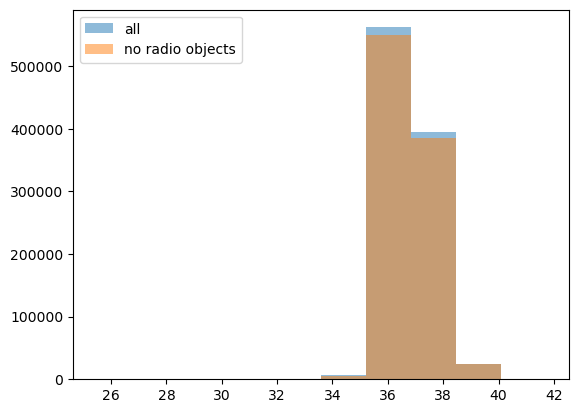

22634


In [37]:
plt.hist(np.log10(data['AGNLUM']), label='all', alpha=0.5)
plt.hist(np.log10(data[data['keep_flag']==True]['AGNLUM']), label='no radio objects', alpha=0.5)
plt.legend()
plt.show()
print(len(data[data['keep_flag']==False]))